# PROJET : PRÉDICTION DU RISQUE DE MALADIE CARDIAQUE


#1. CHARGEMENT DES DONNÉES


In [1]:
pip install tensorflow

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
import tensorflow as tf

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Dense,
    Dropout,
    BatchNormalization
)

from tensorflow.keras.callbacks import EarlyStopping

# 2. CHARGEMENT DES DONNÉES


In [4]:
df = pd.read_csv("/content/cleaned_merged_heart_dataset.csv")

print("\n=== Aperçu des données ===")
print(df.head())

print("\n=== Dimensions ===")
print(df.shape)

print("\n=== Informations ===")
print(df.info())

print("\n=== Statistiques ===")
print(df.describe())


=== Aperçu des données ===
   age  sex  cp  trestbps  chol  fbs  restecg  thalachh  exang  oldpeak  \
0   63    1   3       145   233    1        0       150      0      2.3   
1   37    1   2       130   250    0        1       187      0      3.5   
2   41    0   1       130   204    0        0       172      0      1.4   
3   56    1   1       120   236    0        1       178      0      0.8   
4   57    0   0       120   354    0        1       163      1      0.6   

   slope  ca  thal  target  
0      0   0     1       1  
1      0   0     2       1  
2      2   0     2       1  
3      2   0     2       1  
4      2   0     2       1  

=== Dimensions ===
(1888, 14)

=== Informations ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1888 entries, 0 to 1887
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1888 non-null   int64  
 1   sex       1888 non-null   int64  
 2   cp        1888 non-null   

# 3. QUALITÉ DES DONNÉES

In [5]:
print("\n=== Valeurs manquantes ===")
print(df.isnull().sum())

print("\n=== Doublons ===")
print("Nombre de doublons :", df.duplicated().sum())


=== Valeurs manquantes ===
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalachh    0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

=== Doublons ===
Nombre de doublons : 1286


# 4. ANALYSE EXPLORATOIRE

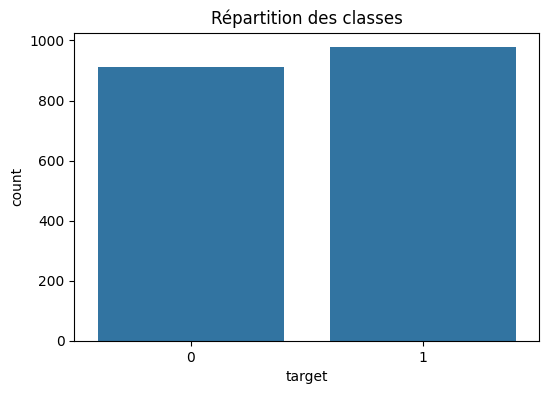

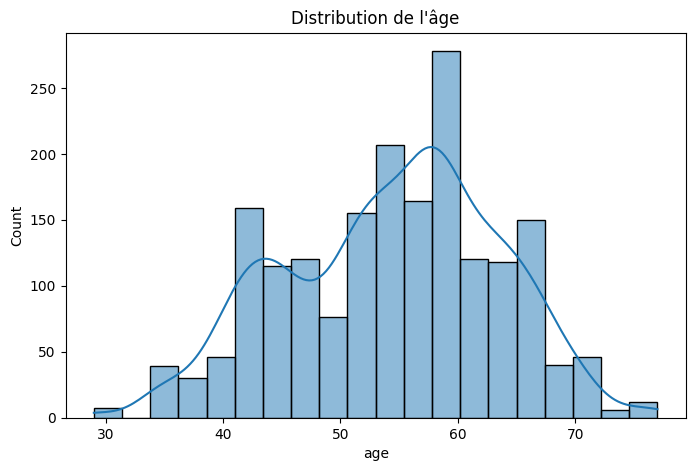

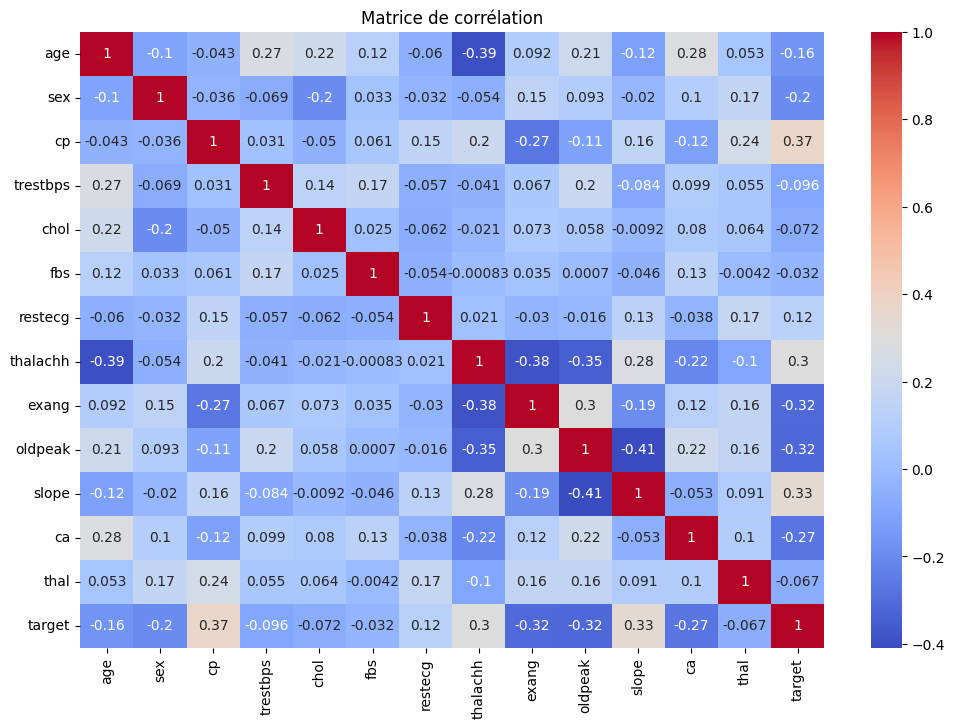

In [6]:
plt.figure(figsize=(6,4))
sns.countplot(x='target', data=df)
plt.title("Répartition des classes")
plt.show()


plt.figure(figsize=(8,5))
sns.histplot(df['age'], bins=20, kde=True)
plt.title("Distribution de l'âge")
plt.show()


plt.figure(figsize=(12,8))
sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm'
)
plt.title("Matrice de corrélation")
plt.show()

# 5. VARIABLES EXPLICATIVES ET CIBLE

In [7]:

X = df.drop("target", axis=1)
y = df["target"]

# 6. SÉPARATION TRAIN / VALIDATION / TEST


In [8]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("\nTrain :", X_train.shape)
print("Validation :", X_valid.shape)
print("Test :", X_test.shape)


Train : (1321, 13)
Validation : (283, 13)
Test : (284, 13)


# 7. NORMALISATION ET FONCTION D'EVALUATION


In [9]:
#NORMALISATION
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_valid_scaled = scaler.transform(X_valid)

X_test_scaled = scaler.transform(X_test)

# =====================================================
# FONCTION D'ÉVALUATION
# =====================================================

def evaluate_model(name, model, Xtest, ytest):

    pred = model.predict(Xtest)

    accuracy = accuracy_score(ytest, pred)
    precision = precision_score(ytest, pred)
    recall = recall_score(ytest, pred)
    f1 = f1_score(ytest, pred)

    print("\n" + "="*50)
    print(name)
    print("="*50)

    print("Accuracy :", round(accuracy, 4))
    print("Precision :", round(precision, 4))
    print("Recall :", round(recall, 4))
    print("F1-score :", round(f1, 4))

    print("\nClassification Report")
    print(classification_report(ytest, pred))

    cm = confusion_matrix(ytest, pred)

    plt.figure(figsize=(5,4))
    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues'
    )
    plt.title(f"Matrice de confusion - {name}")
    plt.show()

    return accuracy, precision, recall, f1

# 8. MODÈLE 1 : RÉGRESSION LOGISTIQUE



Régression Logistique
Accuracy : 0.7007
Precision : 0.6782
Recall : 0.8027
F1-score : 0.7352

Classification Report
              precision    recall  f1-score   support

           0       0.74      0.59      0.66       137
           1       0.68      0.80      0.74       147

    accuracy                           0.70       284
   macro avg       0.71      0.70      0.70       284
weighted avg       0.71      0.70      0.70       284



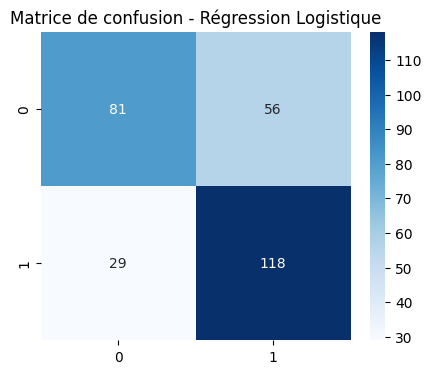

In [10]:
log_reg = LogisticRegression(max_iter=500)

log_reg.fit(
    X_train_scaled,
    y_train
)

results_log = evaluate_model(
    "Régression Logistique",
    log_reg,
    X_test_scaled,
    y_test
)

# 9. MODÈLE 2 : ARBRE DE DÉCISION


Arbre de Décision
Accuracy : 0.8838
Precision : 0.88
Recall : 0.898
F1-score : 0.8889

Classification Report
              precision    recall  f1-score   support

           0       0.89      0.87      0.88       137
           1       0.88      0.90      0.89       147

    accuracy                           0.88       284
   macro avg       0.88      0.88      0.88       284
weighted avg       0.88      0.88      0.88       284



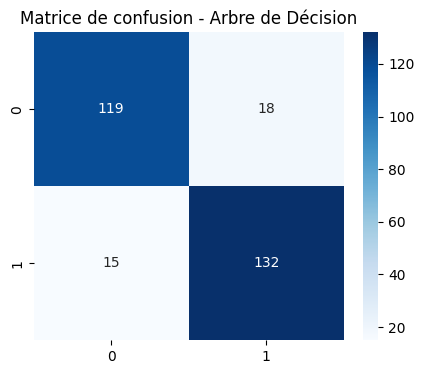

In [11]:
tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

tree.fit(
    X_train,
    y_train
)

results_tree = evaluate_model(
    "Arbre de Décision",
    tree,
    X_test,
    y_test
)

# 10. MODÈLE 3 : RANDOM FOREST


Random Forest
Accuracy : 0.9683
Precision : 0.9662
Recall : 0.9728
F1-score : 0.9695

Classification Report
              precision    recall  f1-score   support

           0       0.97      0.96      0.97       137
           1       0.97      0.97      0.97       147

    accuracy                           0.97       284
   macro avg       0.97      0.97      0.97       284
weighted avg       0.97      0.97      0.97       284



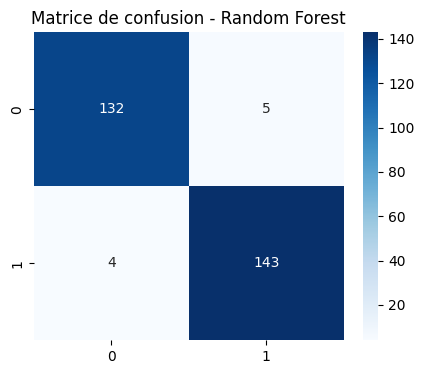

In [12]:
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf.fit(
    X_train,
    y_train
)

results_rf = evaluate_model(
    "Random Forest",
    rf,
    X_test,
    y_test
)

# FONCTION D'ÉVALUATION POUR DEEP LEARNING

In [40]:
def evaluate_dl_model(name, model, Xtest, ytest):

    y_prob = model.predict(Xtest)

    y_pred = (y_prob > 0.5).astype(int)

    accuracy = accuracy_score(ytest, y_pred)
    precision = precision_score(ytest, y_pred)
    recall = recall_score(ytest, y_pred)
    f1 = f1_score(ytest, y_pred)

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Accuracy :", round(accuracy,4))
    print("Precision :", round(precision,4))
    print("Recall :", round(recall,4))
    print("F1-score :", round(f1,4))

    print("\nClassification Report")

    print(classification_report(
        ytest,
        y_pred
    ))

    cm = confusion_matrix(
        ytest,
        y_pred
    )

    plt.figure(figsize=(5,4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Greens'
    )

    plt.title(f"Matrice de confusion - {name}")

    plt.show()

    return accuracy, precision, recall, f1

#11. Modèle 4 : MLP Simple

Epoch 1/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.6018 - loss: 0.6806 - val_accuracy: 0.6749 - val_loss: 0.6102
Epoch 2/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7502 - loss: 0.5477 - val_accuracy: 0.7067 - val_loss: 0.5519
Epoch 3/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7790 - loss: 0.4892 - val_accuracy: 0.7279 - val_loss: 0.5162
Epoch 4/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7888 - loss: 0.4550 - val_accuracy: 0.7420 - val_loss: 0.4901
Epoch 5/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8024 - loss: 0.4302 - val_accuracy: 0.7703 - val_loss: 0.4670
Epoch 6/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8085 - loss: 0.4101 - val_accuracy: 0.7880 - val_loss: 0.4459
Epoch 7/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8145 - loss: 0.3928 - val_accuracy: 0.7809 - val_loss: 0.4236
Epoch 8/50
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8266 - loss: 0.3770 - val_accuracy: 0.7951 - val_loss:

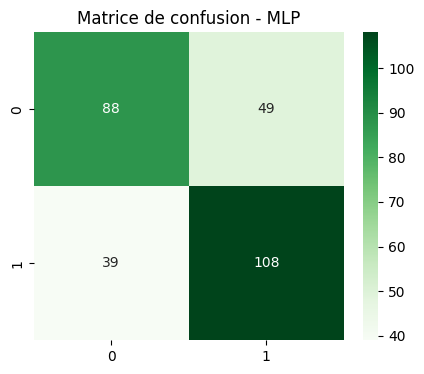

In [41]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

mlp = Sequential([

    Dense(
        32,
        activation='relu',
        input_shape=(X_train_scaled.shape[1],)
    ),

    Dense(
        16,
        activation='relu'
    ),

    Dense(
        1,
        activation='sigmoid'
    )

])

mlp.compile(

    optimizer='adam',

    loss='binary_crossentropy',

    metrics=['accuracy']

)

history_mlp = mlp.fit(

    X_train_scaled,
    y_train,

    validation_data=(
        X_valid_scaled,
        y_valid
    ),

    epochs=50,

    batch_size=32,

    callbacks=[early_stop],

    verbose=1

)

results_mlp = evaluate_dl_model(

    "MLP",

    mlp,

    X_test_scaled,

    y_test

)

#Évaluation MLP

In [42]:
pred_prob = mlp.predict(X_test_scaled)

pred = (pred_prob > 0.5).astype(int)

print(classification_report(y_test, pred))

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
              precision    recall  f1-score   support

           0       0.69      0.64      0.67       137
           1       0.69      0.73      0.71       147

    accuracy                           0.69       284
   macro avg       0.69      0.69      0.69       284
weighted avg       0.69      0.69      0.69       284



# 12. Modèle 5 : Deep Neural Network


---



Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


42/42 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - accuracy: 0.6427 - loss: 0.6378 - val_accuracy: 0.7032 - val_loss: 0.5771
Epoch 2/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7752 - loss: 0.4959 - val_accuracy: 0.7597 - val_loss: 0.4898
Epoch 3/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.7949 - loss: 0.4229 - val_accuracy: 0.7809 - val_loss: 0.4359
Epoch 4/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8304 - loss: 0.3721 - val_accuracy: 0.8021 - val_loss: 0.3780
Epoch 5/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8554 - loss: 0.3286 - val_accuracy: 0.8551 - val_loss: 0.3325
Epoch 6/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.8766 - loss: 0.2849 - val_accuracy: 0.8728 - val_loss: 0.2929
Epoch 7/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9152 - loss: 0.2478 - val_accuracy: 0.8905 - val_loss: 0.2599
Epoch 8/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9228 - loss: 0.2100 - val_accuracy: 0.9117 - val_loss: 

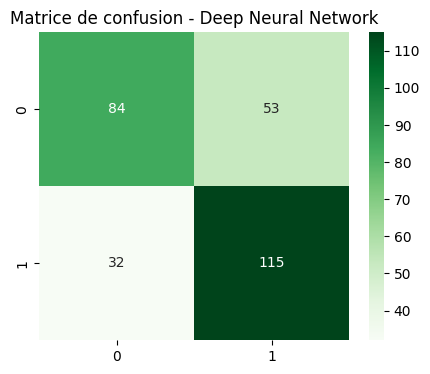

In [50]:
dnn = Sequential([

    Dense(
        64,
        activation='relu',
        input_shape=(X_train_scaled.shape[1],)
    ),

    Dense(
        32,
        activation='relu'
    ),

    Dense(
        16,
        activation='relu'
    ),

    Dense(
        8,
        activation='relu'
    ),

    Dense(
        1,
        activation='sigmoid'
    )

])

dnn.compile(

    optimizer='adam',

    loss='binary_crossentropy',

    metrics=['accuracy']

)

history_dnn = dnn.fit(

    X_train_scaled,
    y_train,

    validation_data=(
        X_valid_scaled,
        y_valid
    ),

    epochs=100,

    batch_size=32,

    callbacks=[early_stop],

    verbose=1

)

results_dnn = evaluate_dl_model(

    "Deep Neural Network",

    dnn,

    X_test_scaled,

    y_test

)

# EVALUATION

In [51]:
pred_prob = dnn.predict(X_test_scaled)

pred = (pred_prob > 0.5).astype(int)

print(classification_report(y_test, pred))

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
              precision    recall  f1-score   support

           0       0.72      0.61      0.66       137
           1       0.68      0.78      0.73       147

    accuracy                           0.70       284
   macro avg       0.70      0.70      0.70       284
weighted avg       0.70      0.70      0.70       284



# Modèle 6 : DNN + Dropout

Epoch 1/100


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


42/42 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6881 - loss: 0.6121 - val_accuracy: 0.7385 - val_loss: 0.5816
Epoch 2/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7797 - loss: 0.4829 - val_accuracy: 0.7491 - val_loss: 0.5317
Epoch 3/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8100 - loss: 0.4325 - val_accuracy: 0.7774 - val_loss: 0.4783
Epoch 4/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8039 - loss: 0.4182 - val_accuracy: 0.8163 - val_loss: 0.4344
Epoch 5/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8206 - loss: 0.3854 - val_accuracy: 0.8481 - val_loss: 0.3911
Epoch 6/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8395 - loss: 0.3663 - val_accuracy: 0.8587 - val_loss: 0.3434
Epoch 7/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8569 - loss: 0.3417 - val_accuracy: 0.8693 - val_loss: 0.3140
Epoch 8/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8531 - loss: 0.3161 - val_accuracy: 0.8975 - val_loss: 0.2

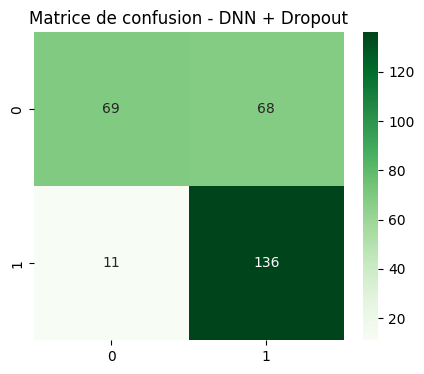

In [52]:
deep_model = Sequential([

    Dense(
        128,
        activation='relu',
        input_shape=(X_train_scaled.shape[1],)
    ),

    BatchNormalization(),

    Dropout(0.3),

    Dense(
        64,
        activation='relu'
    ),

    BatchNormalization(),

    Dropout(0.3),

    Dense(
        32,
        activation='relu'
    ),

    Dense(
        1,
        activation='sigmoid'
    )

])

deep_model.compile(

    optimizer='adam',

    loss='binary_crossentropy',

    metrics=['accuracy']

)

history_deep = deep_model.fit(

    X_train_scaled,
    y_train,

    validation_data=(
        X_valid_scaled,
        y_valid
    ),

    epochs=100,

    batch_size=32,

    callbacks=[early_stop],

    verbose=1

)

results_deep = evaluate_dl_model(

    "DNN + Dropout",

    deep_model,

    X_test_scaled,

    y_test

)

# Evaluation

In [53]:
pred_prob = deep_model.predict(X_test_scaled)

pred = (pred_prob > 0.5).astype(int)

print(classification_report(y_test, pred))

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
              precision    recall  f1-score   support

           0       0.86      0.50      0.64       137
           1       0.67      0.93      0.77       147

    accuracy                           0.72       284
   macro avg       0.76      0.71      0.71       284
weighted avg       0.76      0.72      0.71       284



# Early Stopping

In [55]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(

    monitor='val_loss',

    patience=10,

    restore_best_weights=True

)

history_deep = deep_model.fit(

    X_train_scaled,
    y_train,

    validation_data=(
        X_valid_scaled,
        y_valid
    ),

    epochs=100,

    callbacks=[early_stop]

)

Epoch 1/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9447 - loss: 0.1391 - val_accuracy: 0.9435 - val_loss: 0.1467
Epoch 2/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9394 - loss: 0.1442 - val_accuracy: 0.9399 - val_loss: 0.1516
Epoch 3/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9569 - loss: 0.1154 - val_accuracy: 0.9470 - val_loss: 0.1405
Epoch 4/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9493 - loss: 0.1364 - val_accuracy: 0.9470 - val_loss: 0.1446
Epoch 5/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9508 - loss: 0.1327 - val_accuracy: 0.9435 - val_loss: 0.1540
Epoch 6/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9425 - loss: 0.1394 - val_accuracy: 0.9470 - val_loss: 0.1531
Epoch 7/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9516 - loss: 0.1231 - val_accuracy: 0.9399 - val_loss: 0.1403
Epoch 8/100
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9447 - loss: 0.1316 - val_accuracy: 0.9576 - v

# COURBES D'APPRENTISSAGE

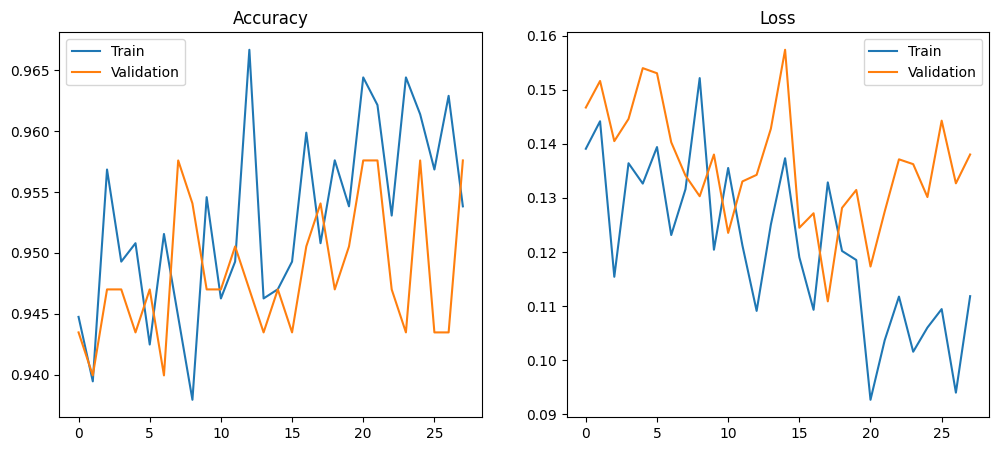

In [56]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(
    history_deep.history['accuracy'],
    label='Train'
)

plt.plot(
    history_deep.history['val_accuracy'],
    label='Validation'
)

plt.title('Accuracy')

plt.legend()

plt.subplot(1,2,2)

plt.plot(
    history_deep.history['loss'],
    label='Train'
)

plt.plot(
    history_deep.history['val_loss'],
    label='Validation'
)

plt.title('Loss')

plt.legend()

plt.show()

#  TABLEAU FINAL DES 6 MODÈLES

In [57]:
comparison = pd.DataFrame({

    "Modèle":[

        "Régression Logistique",
        "Arbre de Décision",
        "Random Forest",
        "MLP",
        "DNN",
        "DNN + Dropout"

    ],

    "Accuracy":[

        results_log[0],
        results_tree[0],
        results_rf[0],
        results_mlp[0],
        results_dnn[0],
        results_deep[0]

    ],

    "Precision":[

        results_log[1],
        results_tree[1],
        results_rf[1],
        results_mlp[1],
        results_dnn[1],
        results_deep[1]

    ],

    "Recall":[

        results_log[2],
        results_tree[2],
        results_rf[2],
        results_mlp[2],
        results_dnn[2],
        results_deep[2]

    ],

    "F1":[

        results_log[3],
        results_tree[3],
        results_rf[3],
        results_mlp[3],
        results_dnn[3],
        results_deep[3]

    ]

})

print(comparison)

                  Modèle  Accuracy  Precision    Recall        F1
0  Régression Logistique  0.700704   0.678161  0.802721  0.735202
1      Arbre de Décision  0.883803   0.880000  0.897959  0.888889
2          Random Forest  0.968310   0.966216  0.972789  0.969492
3                    MLP  0.690141   0.687898  0.734694  0.710526
4                    DNN  0.700704   0.684524  0.782313  0.730159
5          DNN + Dropout  0.721831   0.666667  0.925170  0.774929


# Visualisation des performances

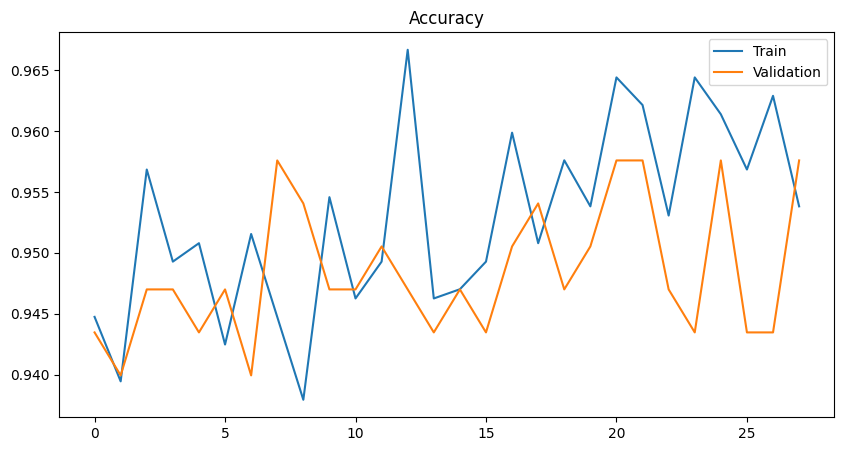

In [58]:
history = history_deep

plt.figure(figsize=(10,5))

plt.plot(
    history.history['accuracy'],
    label='Train'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation'
)

plt.title("Accuracy")
plt.legend()

plt.show()

# 12. GRAPHIQUE DE COMPARAISON

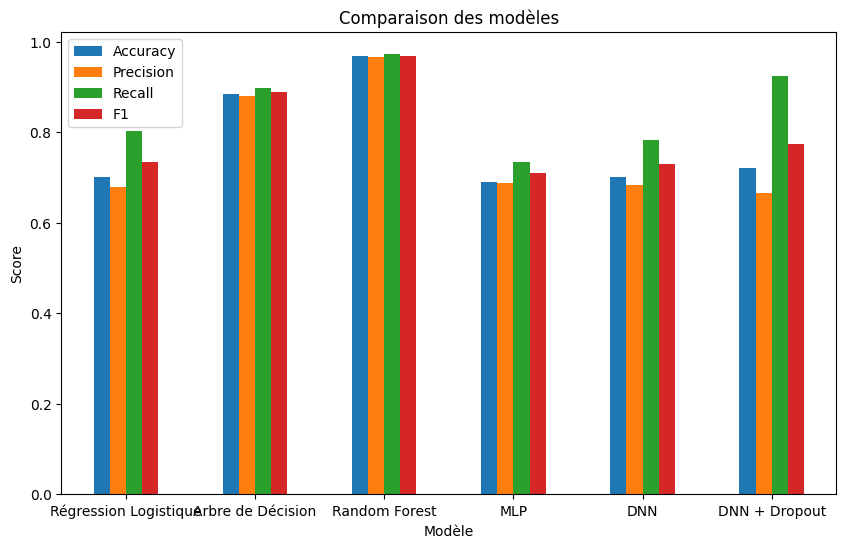

In [59]:
comparison.set_index("Modèle").plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Comparaison des modèles")
plt.ylabel("Score")
plt.xticks(rotation=0)

plt.show()

# 13. IMPORTANCE DES VARIABLES


=== Importance des variables ===
    Variable  Importance
12      thal    0.146171
2         cp    0.129137
7   thalachh    0.114690
0        age    0.085525
9    oldpeak    0.085007
4       chol    0.083161
11        ca    0.083006
10     slope    0.080262
3   trestbps    0.073225
8      exang    0.041915
6    restecg    0.039194
1        sex    0.027183
5        fbs    0.011524


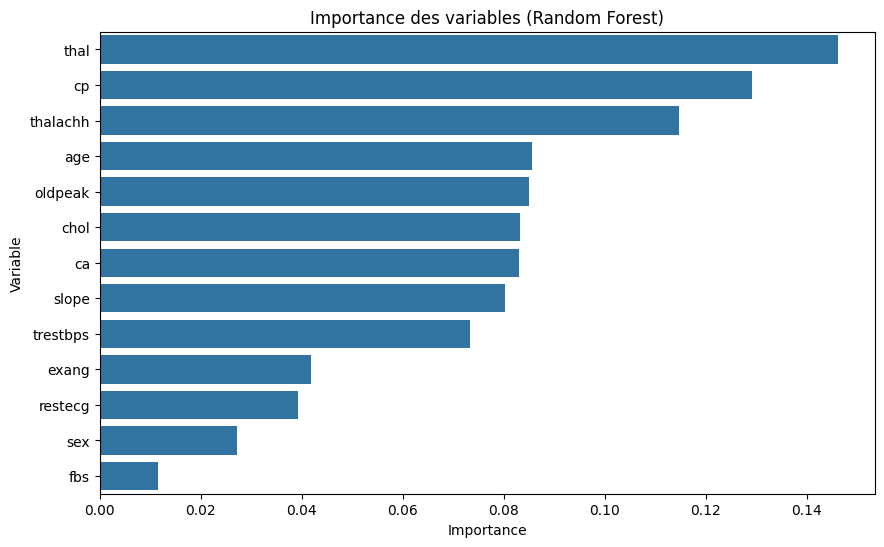


Analyse terminée.


In [60]:
importance = pd.DataFrame({

    "Variable": X.columns,
    "Importance": rf.feature_importances_

})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print("\n=== Importance des variables ===")
print(importance)

plt.figure(figsize=(10,6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Variable"
)

plt.title("Importance des variables (Random Forest)")
plt.show()

print("\nAnalyse terminée.")